<a href="https://colab.research.google.com/github/Bianca-21-bit/Relatorio/blob/main/Modelos%20de%20Machine%20Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Importando as Bibliotecas

In [ ]:

# <> ------------------------------------------------------
# <> Verificando se o pacote está instalado
# <> o símbolo % é para executar no bash
%pip show pycaret

In [ ]:
# <> ------------------------------------------------------
# <> Instalando o PyCaret 3.3.2 no Python 3.13 do Colab
# <> --no-deps => instala o PyCaret sem rebaixar numpy, pandas e scipy do Colab
%pip install -q pycaret==3.3.2 --no-deps

# <> Dependências do PyCaret (as que já existem no Colab são mantidas)
# <> scikit-learn 1.5.2 e joblib 1.3.2 são as versões compatíveis com o PyCaret 3.3.2
%pip install -q "scikit-learn==1.5.2" "joblib==1.3.2" "schemdraw==0.15" \
    pyod imbalanced-learn category-encoders lightgbm numba scikit-plot \
    yellowbrick plotly plotly-resampler statsmodels deprecation xxhash wurlitzer setuptools

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pycaret 3.3.2 requires kaleido>=0.2.1, which is not installed.
pycaret 3.3.2 requires pmdarima>=2.0.4, which is not installed.
pycaret 3.3.2 requires sktime==0.26.0, which is not installed.
pycaret 3.3.2 requires tbats>=1.1.3, which is not installed.
pycaret 3.3.2 requires matplotlib<3.8.0, but you have matplotlib 3.10.0 which is incompatible.
pycaret 3.3.2 requires numpy<1.27,>=1.21, but you have numpy 2.4.6 which is incompatible.
pycaret 3.3.2 requires pandas<2.2.0, but you have pandas 2.2.3 which is incompatible.
pycaret 3.3.2 requires scipy<=1.11.4,>=1.6.1, but you have scipy 1.16.3 which is incompatible.
tobler 0.14.0 requires joblib>=1.4, but you have joblib 1.3.2 which is incompatible.
hdbscan 0.8.44 requires scikit-learn>=1.6, but you have scikit-learn 1.5.2 which is incompatible.
umap-learn 0.5.12 require

In [ ]:
# <> ------------------------------------------------------
# <> Ajustes de compatibilidade do PyCaret 3.3.2 com Python 3.13 / numpy 2
# <> (só altera os arquivos da biblioteca instalada; pode rodar quantas vezes quiser)
import importlib.util, pathlib, re

# o módulo distutils foi removido do Python 3.12+; o setuptools fornece um substituto
DISTUTILS = (r'(?<!import setuptools  # distutils\n)from distutils\.version import LooseVersion',
             'import setuptools  # distutils\nfrom distutils.version import LooseVersion')

ajustes = {
    'pycaret': [
        # PyCaret bloqueia Python >= 3.12 na importação
        (r'elif sys\.version_info >= \(3, 12\):', 'elif False:'),
        # função que mudou de lugar no scikit-learn
        (r'from sklearn\.utils import _print_elapsed_time',
         'from sklearn.utils._user_interface import _print_elapsed_time'),
        # funções removidas no numpy 2
        (r'np\.product\(', 'np.prod('),
        (r'np\.NaN\b', 'np.nan'),
        DISTUTILS,
    ],
    'yellowbrick': [
        DISTUTILS,
    ],
    'scikitplot': [
        # função removida do scipy (usada pelo scikit-plot)
        (r'from scipy import interp\b', 'from numpy import interp'),
    ],
}

for pacote, regras in ajustes.items():
    pasta = pathlib.Path(importlib.util.find_spec(pacote).submodule_search_locations[0])
    for arquivo in pasta.rglob('*.py'):
        texto = original = arquivo.read_text(encoding='utf-8')
        for padrao, novo in regras:
            texto = re.sub(padrao, novo, texto)
        if texto != original:
            arquivo.write_text(texto, encoding='utf-8')
            print('Ajustado:', arquivo.relative_to(pasta.parent))

print('Pronto! O PyCaret já pode ser importado.')

Ajustado: pycaret/__init__.py
Ajustado: pycaret/internal/pipeline.py
Ajustado: pycaret/utils/_dependencies.py
Ajustado: pycaret/internal/preprocess/preprocessor.py
Ajustado: pycaret/internal/patches/sklearn.py
Ajustado: yellowbrick/style/colors.py
Ajustado: yellowbrick/style/rcmod.py
Ajustado: scikitplot/plotters.py
Ajustado: scikitplot/metrics.py
Pronto! O PyCaret já pode ser importado.


In [ ]:
import sys
import pycaret
import sklearn
import pandas as pd
import numpy as np

print("Python version:", sys.version.split()[0])
print("PyCaret version:", pycaret.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("Pandas version:", pd.__version__)
print("Numpy version:", np.__version__)

Python version: 3.13.18
PyCaret version: 3.3.2
Scikit-learn version: 1.5.2
Pandas version: 2.2.3
Numpy version: 2.4.6


In [ ]:
# <> ------------------------------------------------------
# <> Verificando se o pacote foi instalado
%pip show pycaret

Name: pycaret
Version: 3.3.2
Summary: PyCaret - An open source, low-code machine learning library in Python.
Home-page: https://github.com/pycaret/pycaret
Author: Moez Ali
Author-email: moez.ali@queensu.ca
License: MIT
Location: /usr/local/lib/python3.13/dist-packages
Requires: category-encoders, cloudpickle, deprecation, imbalanced-learn, importlib-metadata, ipython, ipywidgets, jinja2, joblib, kaleido, lightgbm, markupsafe, matplotlib, nbformat, numba, numpy, pandas, plotly, plotly-resampler, pmdarima, psutil, pyod, requests, schemdraw, scikit-learn, scikit-plot, scipy, sktime, statsmodels, tbats, tqdm, wurlitzer, xxhash, yellowbrick
Required-by: 


In [ ]:
import sys
import numpy
import sklearn
import setuptools

print("Python:", sys.version)
print("NumPy:", numpy.__version__)
print("Scikit-Learn:", sklearn.__version__)
print("Setuptools:", setuptools.__version__)

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
NumPy: 2.4.6
Scikit-Learn: 1.5.2
Setuptools: 80.10.2


In [ ]:
# <> -----------------------------------------------------
# Lendo as bibliotecas necessárias

# <> -----------------------------
# <> Bibliotecas dos algoritmos
from pycaret.classification import *
from sklearn.tree import plot_tree
from sklearn.metrics import confusion_matrix, accuracy_score, cohen_kappa_score, classification_report
from sklearn.tree import export_text

# <> Bibliotecas de Visualização
import seaborn as sns
import matplotlib.pyplot as plt

# <> Biliotecas para manipulação com dados
import pandas as pd

## Modelo 1: Árvore de Decisão

# Forma 1 - Utilizando dados separados para treino e teste manualmente

In [ ]:
import pandas as pd

arquivo = pd.read_csv("/content/sleep_debt_screen_time.csv")

In [ ]:
# Para ver se a base de dados é balanceada
print(arquivo['sleep_debt_category'].value_counts())

sleep_debt_category
Mild        4393
Moderate    2361
No Debt     1721
Severe        25
Name: count, dtype: int64


Com esse resultado, vemos que a base de dados é muito desbalanceada

In [ ]:
# Agrupando duas classes, pois a classe severe é muito inferior das outras classes

arquivo['sleep_debt_category'] = arquivo['sleep_debt_category'].replace({
    'Severe': 'Moderate'
})

In [ ]:
# <> Vendo as classes depois do agrupamento
arquivo['sleep_debt_category'].value_counts()

,count
sleep_debt_category,
Mild,4393
Moderate,2386
No Debt,1721


In [ ]:
arquivo.head()

,user_id,age,gender,chronotype,occupation,bedtime_hour,screen_time_before_bed_min,primary_app_category,screen_brightness_pct,blue_light_filter_on,...,room_temperature_f,ambient_noise_db,sleep_onset_latency_min,total_sleep_hours,rem_sleep_pct,deep_sleep_pct,awakenings_count,sleep_efficiency_pct,next_day_fatigue_score,sleep_debt_category
0,1,32,Female,Intermediate,Student,23.94,102,Social Media,100,False,...,73.5,32.6,60.3,5.67,15.2,13.5,11,63.7,8.85,Moderate
1,2,26,Female,Intermediate,Student,0.06,14,Short-Form Video,87,True,...,66.8,44.3,24.5,7.42,16.9,22.3,1,92.9,2.98,No Debt
2,3,34,Male,Night Owl,Professional,1.48,58,Messaging,76,True,...,68.0,45.6,21.9,6.98,20.2,18.5,2,84.6,3.90,Mild
3,4,43,Female,Intermediate,Professional,22.42,48,Social Media,56,False,...,72.3,42.3,34.5,7.67,14.4,17.3,6,79.9,4.81,No Debt
4,5,25,Male,Early Bird,Professional,22.43,29,Streaming,96,True,...,80.1,10.0,37.4,6.31,16.6,16.1,0,89.3,3.88,Mild


In [ ]:
print(arquivo.columns.tolist())

['user_id', 'age', 'gender', 'chronotype', 'occupation', 'bedtime_hour', 'screen_time_before_bed_min', 'primary_app_category', 'screen_brightness_pct', 'blue_light_filter_on', 'caffeine_intake_mg', 'caffeine_last_hour', 'physical_activity_min', 'room_temperature_f', 'ambient_noise_db', 'sleep_onset_latency_min', 'total_sleep_hours', 'rem_sleep_pct', 'deep_sleep_pct', 'awakenings_count', 'sleep_efficiency_pct', 'next_day_fatigue_score', 'sleep_debt_category']


# Variáveis:
* Age: Representa a idade do usuário (em anos).
* Gender: Representa o gênero do usuário.
* Chronotype: Representa o perfil biológico de sono do usuário.
* Occupation: Representa a ocupação do usuário.
* Bedtime_Hour: Representa o horário em que o usuário costuma dormir.
* Screen_Time_Before_Bed_Min: Representa o tempo de uso de tela antes de dormir (em minutos).
* Primary_App_Category: Representa a categoria principal do aplicativo utilizado antes de dormir.
* Screen_Brightness_Pct: Representa o nível de brilho da tela (em percentual).
* Blue_Light_Filter_On: Representa se o filtro de luz azul está ativado.
* Physical_Activity_Min: Representa o tempo diário de atividade física (em minutos).
* Room_Temperature_F: Representa a temperatura do ambiente de sono (em graus Fahrenheit).
* Ambient_Noise_DB: Representa o nível de ruído do ambiente (em decibéis).
* Sleep_Onset_Latency_Min: Representa o tempo necessário para adormecer (em minutos).
* Total_Sleep_Hours: Representa a quantidade total de horas dormidas.
* REM_Sleep_Pct: Representa a porcentagem do sono REM.
* Deep_Sleep_Pct: Representa a porcentagem do sono profundo.
* Awakenings_Count: Representa o número de despertares durante a noite.
* Sleep_Efficiency_Pct: Representa a eficiência do sono (em percentual).
* Next_Day_Fatigue_Score: Representa o nível de fadiga observado no dia seguinte.

## Variável categorica (Class):

* Next_Day_Fatigue_Score: Representa o nível de fadiga do usuário no dia seguinte e é a variável a ser prevista pelo modelo.



In [ ]:
from sklearn.model_selection import train_test_split

# X = todas as colunas exceto a variável categorica
X = arquivo.drop("sleep_debt_category", axis=1)

# y = variável categorica
y = arquivo["sleep_debt_category"]

# Divisão treino/teste
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2, # 20% para teste
    random_state=10,
    stratify=y  # importante se houber desbalanceamento
)

print("Treino:", X_train.shape)
print("Teste:", X_test.shape)


Treino: (6800, 22)
Teste: (1700, 22)


In [ ]:
# <> ------------------------------------------------------
# <> Verificando se os tipos foram lidos corretamente
print(X_train.dtypes)
print(X_test.dtypes)

user_id                         int64
age                             int64
gender                         object
chronotype                     object
occupation                     object
bedtime_hour                  float64
screen_time_before_bed_min      int64
primary_app_category           object
screen_brightness_pct           int64
blue_light_filter_on             bool
caffeine_intake_mg              int64
caffeine_last_hour            float64
physical_activity_min           int64
room_temperature_f            float64
ambient_noise_db              float64
sleep_onset_latency_min       float64
total_sleep_hours             float64
rem_sleep_pct                 float64
deep_sleep_pct                float64
awakenings_count                int64
sleep_efficiency_pct          float64
next_day_fatigue_score        float64
dtype: object
user_id                         int64
age                             int64
gender                         object
chronotype                     objec

In [ ]:
X_train.head()

,user_id,age,gender,chronotype,occupation,bedtime_hour,screen_time_before_bed_min,primary_app_category,screen_brightness_pct,blue_light_filter_on,...,physical_activity_min,room_temperature_f,ambient_noise_db,sleep_onset_latency_min,total_sleep_hours,rem_sleep_pct,deep_sleep_pct,awakenings_count,sleep_efficiency_pct,next_day_fatigue_score
6547,6548,19,Female,Night Owl,Professional,0.13,34,Social Media,66,True,...,1,71.5,45.9,28.5,7.67,17.1,18.1,3,79.6,3.39
3388,3389,36,Female,Early Bird,Student,22.96,66,Social Media,57,True,...,66,71.8,18.2,33.7,7.09,17.6,16.4,4,83.4,4.40
7007,7008,41,Female,Night Owl,Unemployed,2.78,65,Messaging,100,True,...,37,63.7,30.1,17.8,5.49,17.7,17.4,2,84.9,5.26
4562,4563,19,Male,Night Owl,Retired,23.93,51,Streaming,43,True,...,75,71.4,29.2,29.5,7.00,20.9,22.4,2,87.7,3.88
2345,2346,38,Male,Intermediate,Student,23.32,29,Social Media,65,False,...,90,71.4,12.2,35.2,6.44,16.1,19.8,0,87.4,4.51


In [ ]:
# <> Juntando as variável alvo aos dados de treino
train_data = X_train.copy()
train_data['sleep_debt_category'] = y_train

# <> Juntando as variável alvo aos dados de teste
test_data = X_test.copy()
test_data['sleep_debt_category'] = y_test

In [ ]:
# <> ----------------------------------------------------------
# <> Configurar o ambiente PyCaret com dados de treino e teste informados manualmente
from pycaret.classification import setup

cdt = setup(
    data=train_data,
    target='sleep_debt_category',
    test_data=test_data,
    session_id=10,
    index=False
)

,Description,Value
0,Session id,10
1,Target,sleep_debt_category
2,Target type,Multiclass
3,Target mapping,"Mild: 0, Moderate: 1, No Debt: 2"
4,Original data shape,"(8500, 23)"
5,Transformed data shape,"(8500, 37)"
6,Transformed train set shape,"(6800, 37)"
7,Transformed test set shape,"(1700, 37)"
8,Numeric features,17
9,Categorical features,4


In [ ]:
# <> ----------------------------------------
# <> Verificando modelos disponíveis
models()

,Name,Reference,Turbo
ID,,,
lr,Logistic Regression,sklearn.linear_model._logistic.LogisticRegression,True
knn,K Neighbors Classifier,sklearn.neighbors._classification.KNeighborsCl...,True
nb,Naive Bayes,sklearn.naive_bayes.GaussianNB,True
dt,Decision Tree Classifier,sklearn.tree._classes.DecisionTreeClassifier,True
svm,SVM - Linear Kernel,sklearn.linear_model._stochastic_gradient.SGDC...,True
rbfsvm,SVM - Radial Kernel,sklearn.svm._classes.SVC,False
gpc,Gaussian Process Classifier,sklearn.gaussian_process._gpc.GaussianProcessC...,False
mlp,MLP Classifier,sklearn.neural_network._multilayer_perceptron....,False
ridge,Ridge Classifier,sklearn.linear_model._ridge.RidgeClassifier,True


In [ ]:
# <> -----------------------------------------------------------
# <> Criando o modelo 'dt' : Decision Tree
decision_tree_model = create_model('dt', max_depth = 3, min_samples_split = 2, cross_validation = False)

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Test,0.7865,0.8559,0.7865,0.8489,0.7701,0.6139,0.6657


Processing:   0%|          | 0/4 [00:00<?, ?it/s]

* Accuracy = 78.65%: o modelo
classificou corretamente cerca de 79% das amostras.
* AUC = 0,8559: excelente capacidade de separação entre as classes. Valores acima de 0,80 geralmente são considerados muito bons.
* Precision = 84,89%: quando o modelo faz uma previsão, ele tende a acertar bastante.
* Recall = 78,65%: o modelo encontra cerca de 79% dos casos reais de cada classe.
* F1-Score = 77,01%: equilíbrio entre precisão e recall.
* Kappa = 0,6139: concordância moderada a substancial acima do acaso.
* MCC = 0,6657: mostra uma boa qualidade geral da classificação, especialmente quando há desbalanceamento entre classes



In [ ]:
# <> ------------------------------------------------------------
# <> Visualizando o modelo
print(decision_tree_model)

DecisionTreeClassifier(ccp_alpha=0.0, class_weight=None, criterion='gini',
                       max_depth=3, max_features=None, max_leaf_nodes=None,
                       min_impurity_decrease=0.0, min_samples_leaf=1,
                       min_samples_split=2, min_weight_fraction_leaf=0.0,
                       monotonic_cst=None, random_state=10, splitter='best')


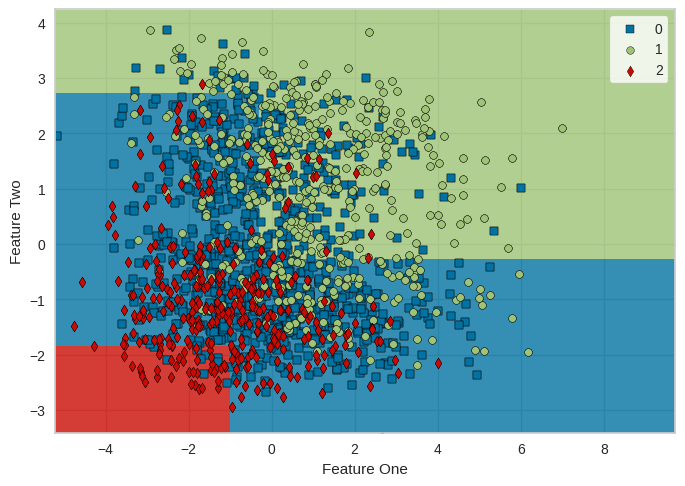

In [ ]:
# <> -------------------------------------------------------------
# <> Visualizando em forma de Gráfico
plot_model(decision_tree_model, plot = 'boundary')

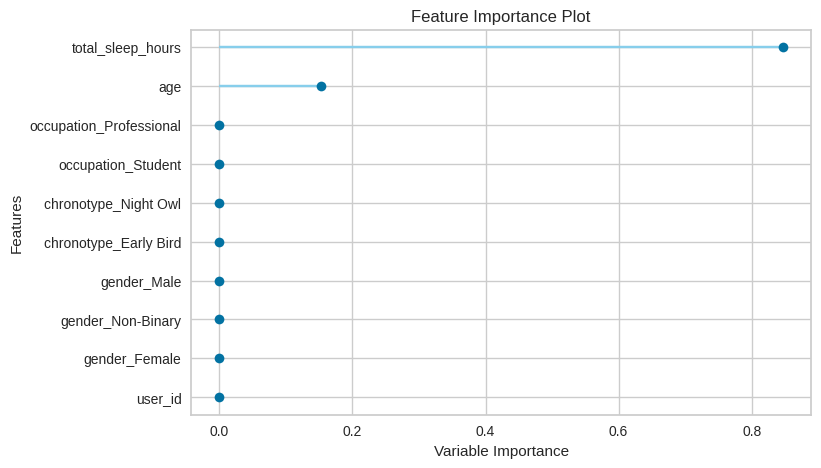

In [ ]:
# <> -------------------------------------------------------------
# <> Visualizando em forma de Gráfico
# <> As variáveis mais importantes
plot_model(decision_tree_model, plot = 'feature')

In [ ]:
# <> -----------------------------------------------------------
# <> Visualizando a estrutura da Árvore
# <> feature_names = nomes das variáveis esplicativas (A e B), sem a coluna sleep_debt_category)
estrutura_DT = export_text(decision_tree_model, feature_names=list(get_config('X_train_transformed').columns))
print(estrutura_DT)

|--- total_sleep_hours <= 6.01
|   |--- age <= 44.50
|   |   |--- class: 1
|   |--- age >  44.50
|   |   |--- total_sleep_hours <= 5.50
|   |   |   |--- class: 1
|   |   |--- total_sleep_hours >  5.50
|   |   |   |--- class: 0
|--- total_sleep_hours >  6.01
|   |--- total_sleep_hours <= 8.01
|   |   |--- age <= 24.50
|   |   |   |--- class: 0
|   |   |--- age >  24.50
|   |   |   |--- class: 0
|   |--- total_sleep_hours >  8.01
|   |   |--- class: 2



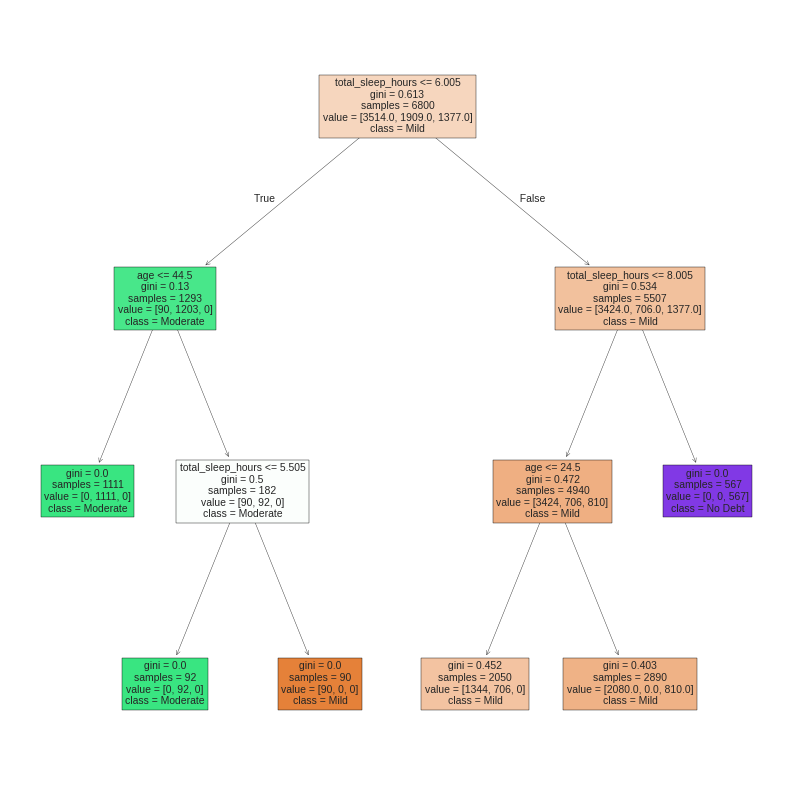

In [ ]:
# <> -----------------------------------------------------------
# <> Plotar a árvore de decisão
plt.figure(figsize=(10,10))
plot_tree(decision_tree_model, filled=True, feature_names=list(get_config('X_train_transformed').columns),
          class_names=sorted(y_test.unique()))
plt.show()

In [ ]:
# <> -----------------------------------------------------------
# <> Fazendo predição do modelo usando o DataFrame de teste completo
dt_testing_pred = predict_model(
    decision_tree_model,
    data = test_data
)

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Decision Tree Classifier,0.7865,0.8559,0.7865,0.8489,0.7701,0.6139,0.6657


Resumo das Métricas:

*  Accuracy: Mede a taxa de acerto geral
*  AUC: Mede a capacidade de discriminação do modelo
*  Recall: Mede a capacidade de identificar positivos reais
*  Precision: Mede a confiabilidade das previsões positivas
*  F1: Equilibra Precision e Recall
*  Kappa: Mede a concordância ajustada ao acaso
*  MCC: Mede a correlação entre previsões e valores reais, robusta e desbalanceamentos



In [ ]:
# <> -----------------------------------------------------
# <> Visualizando Cabeçalho do Data.Frame
dt_testing_pred.head()

,user_id,age,gender,chronotype,occupation,bedtime_hour,screen_time_before_bed_min,primary_app_category,screen_brightness_pct,blue_light_filter_on,...,sleep_onset_latency_min,total_sleep_hours,rem_sleep_pct,deep_sleep_pct,awakenings_count,sleep_efficiency_pct,next_day_fatigue_score,sleep_debt_category,prediction_label,prediction_score
0,7295,29,Female,Intermediate,Freelancer,23.870001,50,E-Reading,69,False,...,36.099998,5.79,18.299999,15.2,1,83.599998,4.74,Moderate,Moderate,1.0000
1,5200,37,Female,Early Bird,Unemployed,21.889999,61,Short-Form Video,59,True,...,38.200001,5.52,18.000000,19.1,0,83.800003,5.39,Moderate,Moderate,1.0000
2,4581,30,Male,Intermediate,Freelancer,22.450001,76,Streaming,65,False,...,43.400002,5.39,17.799999,13.7,2,81.800003,6.18,Moderate,Moderate,1.0000
3,1341,29,Male,Intermediate,Professional,23.850000,68,Short-Form Video,85,True,...,40.500000,6.41,18.000000,13.4,2,79.099998,5.58,Mild,Mild,0.7197
4,5551,18,Male,Night Owl,Professional,0.780000,74,Gaming,44,False,...,39.900002,7.23,14.200000,19.5,1,86.800003,4.55,Mild,Mild,0.6556


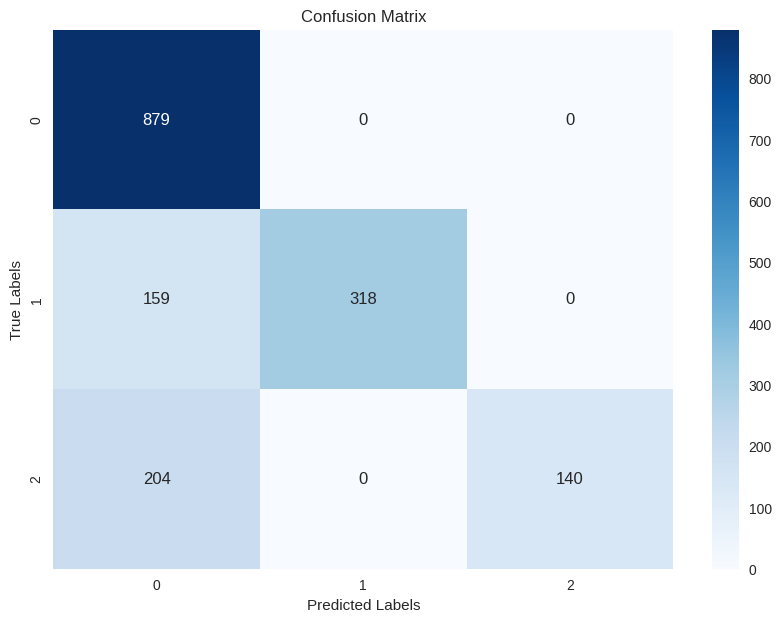

Accuracy: 0.7864705882352941
Kappa: 0.6139351215813458
Classification Report: 
              precision    recall  f1-score   support

        Mild       0.71      1.00      0.83       879
    Moderate       1.00      0.67      0.80       477
     No Debt       1.00      0.41      0.58       344

    accuracy                           0.79      1700
   macro avg       0.90      0.69      0.74      1700
weighted avg       0.85      0.79      0.77      1700



In [ ]:
# Supondo que 'true_labels' seja a coluna de rótulos verdadeiros e 'predicted_labels' a coluna de rótulos previstos
true_labels = dt_testing_pred['sleep_debt_category']
predicted_labels = dt_testing_pred['prediction_label']

# Calcular a matriz de confusão
conf_matrix = confusion_matrix(true_labels, predicted_labels)

# Plotar a matriz de confunsão
plt.figure(figsize=(10,7))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()

# Calcular Acurácia
accuracy = accuracy_score(true_labels, predicted_labels)

# Calcular coeficiente Kappa
kappa = cohen_kappa_score(true_labels, predicted_labels)

# Gerar relatório de classificação
classification_rep = classification_report(true_labels, predicted_labels)

# Exibir as métricas
print(f'Accuracy: {accuracy}')
print(f'Kappa: {kappa}')
print('Classification Report: ')
print(classification_rep)


# Forma 2 - Passando os dados e fazendo separação de treino e teste e usando k-folf automatizados

In [ ]:
# <> ---------------------------------------------------------
# <> Lendo um dataset Completo
url_dat = '/content/sleep_debt_screen_time.csv' # url do dataset de treino

# Carregando o DataFrame antes de usá-lo
arquivo_dat = pd.read_csv(url_dat)

arquivo_dat['sleep_debt_category'] = arquivo_dat['sleep_debt_category'].replace({
    'Severe': 'Moderate'
})



In [ ]:
# <> ---------------------------------------------------------
# <> Verificando tipos das variáveis
arquivo_dat.dtypes

,0
user_id,int64
age,int64
gender,object
chronotype,object
occupation,object
bedtime_hour,float64
screen_time_before_bed_min,int64
primary_app_category,object
screen_brightness_pct,int64
blue_light_filter_on,bool


In [ ]:
# <> Iniciando a configuração do modelo
# <> e informando a variável resposta
# <> session_id => para reprodutibilidade
clf = setup(
    data = arquivo_dat,
    target = 'sleep_debt_category',
    session_id = 12345,
    train_size=0.8, # Reservar 80% dos registros para treinamento; pois 20% restantes ficam para teste(holdout)
    data_split_stratify=True # Preservar a proporção das classes na divisão entre treino e teste
)

,Description,Value
0,Session id,12345
1,Target,sleep_debt_category
2,Target type,Multiclass
3,Target mapping,"Mild: 0, Moderate: 1, No Debt: 2"
4,Original data shape,"(8500, 23)"
5,Transformed data shape,"(8500, 37)"
6,Transformed train set shape,"(6800, 37)"
7,Transformed test set shape,"(1700, 37)"
8,Numeric features,17
9,Categorical features,4


In [ ]:
# <> -------------------------------------------------------
# <> Criação do Modelo com Árvore de Decisão
decision_tree_model = create_model(
    'dt',
    max_depth = 10,
    fold = 5
)

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.4860,0.4999,0.4860,0.3703,0.3767,-0.0028,-0.0042
1,0.4809,0.4973,0.4809,0.3752,0.3814,-0.0048,-0.0066
2,0.4971,0.4955,0.4971,0.3787,0.3720,-0.0057,-0.0102
3,0.4647,0.5194,0.4647,0.3917,0.3959,-0.0018,-0.0021
4,0.4926,0.4974,0.4926,0.3922,0.3869,0.0099,0.0145
Mean,0.4843,0.5019,0.4843,0.3816,0.3826,-0.0010,-0.0017
Std,0.0112,0.0089,0.0112,0.0088,0.0083,0.0056,0.0085


Processing:   0%|          | 0/4 [00:00<?, ?it/s]

In [ ]:
# <> --------------------------------------------------------
# <> Visualizando o modelo
print(decision_tree_model)


DecisionTreeClassifier(ccp_alpha=0.0, class_weight=None, criterion='gini',
                       max_depth=10, max_features=None, max_leaf_nodes=None,
                       min_impurity_decrease=0.0, min_samples_leaf=1,
                       min_samples_split=2, min_weight_fraction_leaf=0.0,
                       monotonic_cst=None, random_state=12345, splitter='best')


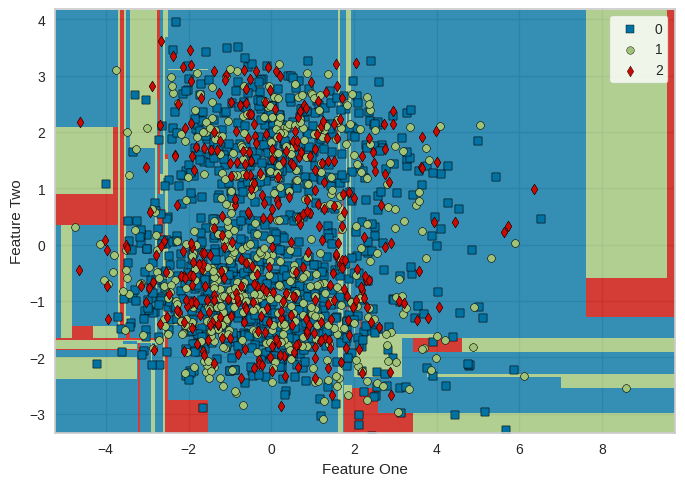

In [ ]:
# <> -----------------------------------------------
# <> Visualizando em forma de Gráfico
plot_model(decision_tree_model, plot = 'boundary')

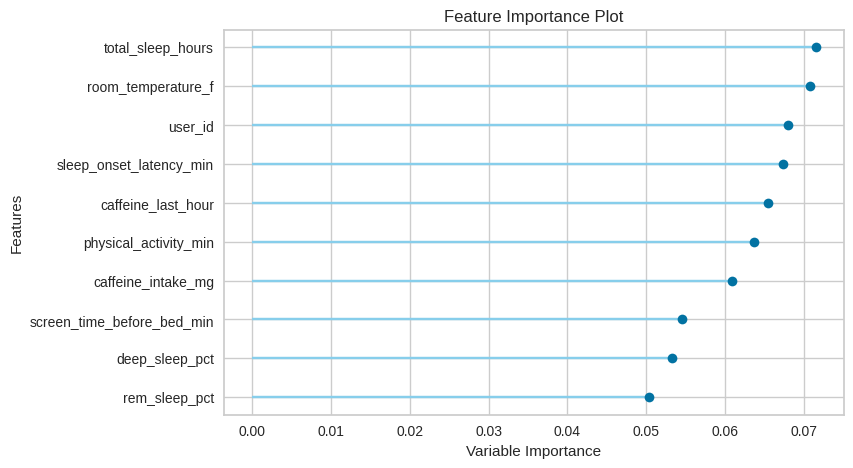

In [ ]:
# <> ----------------------------------------------
# <> Visualizando em forma de Gráfico
plot_model(decision_tree_model, plot = 'feature')

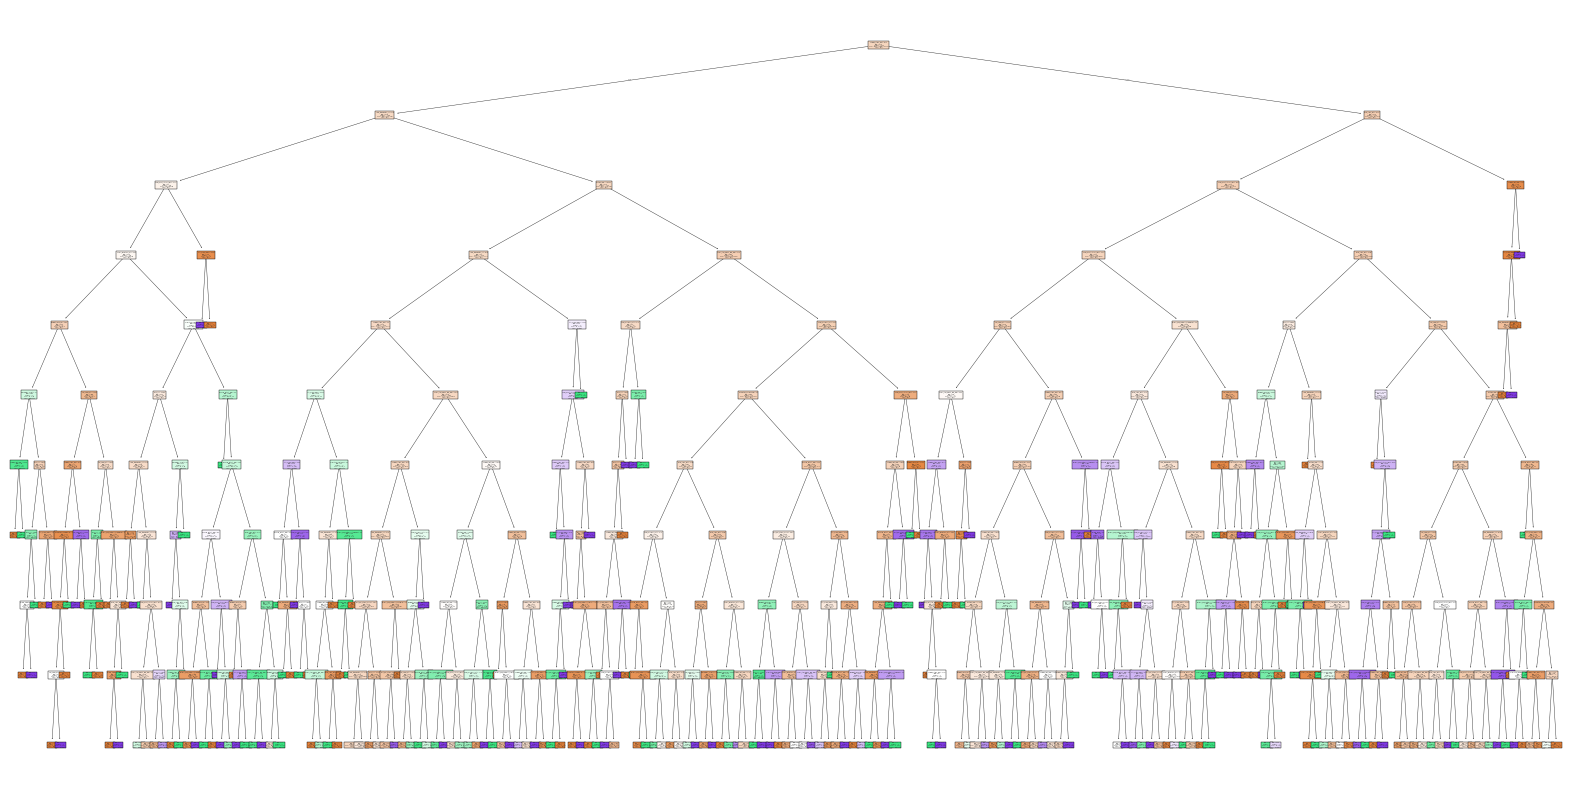

In [ ]:
# <> ---------------------------------------------------
# <> Plotar a árvore de decisão
plt.figure(figsize=(20, 10))
plot_tree(decision_tree_model, filled=True, feature_names=list(get_config('X_train_transformed').columns),
          class_names=sorted(y_test.unique())) # Ajustado para obter as classes diretamente de y_test
plt.show()

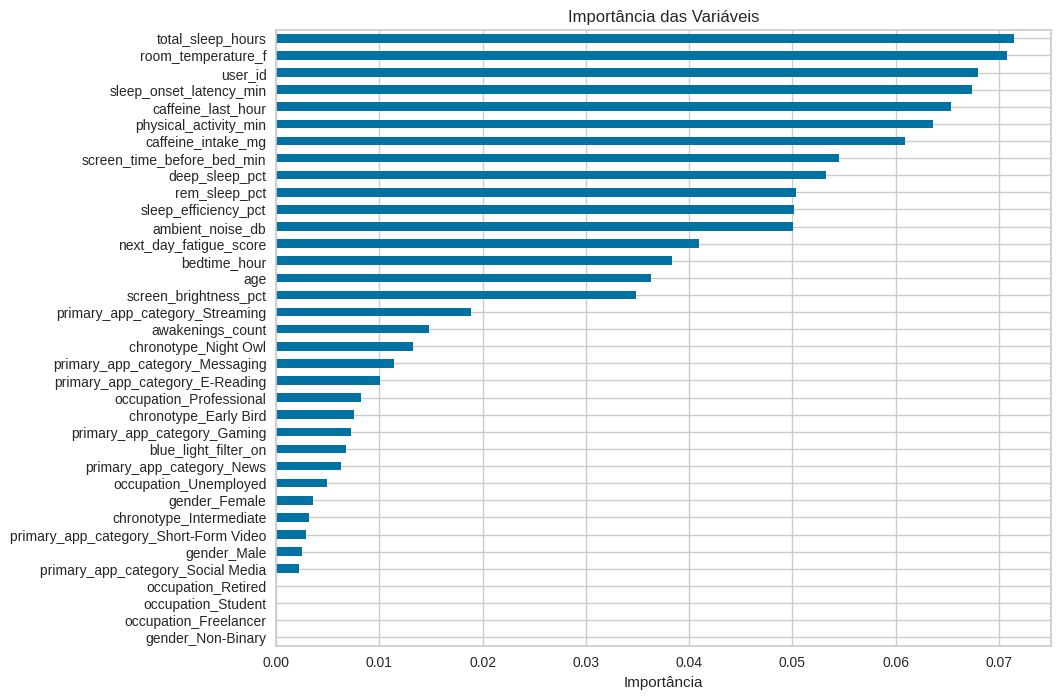

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Obtendo as colunas transformadas pelo pipeline do PyCaret (36 colunas)
features_transformadas = get_config('X_train_transformed').columns

importancias = pd.Series(
    decision_tree_model.feature_importances_,
    index=features_transformadas
)

importancias.sort_values().plot(
    kind='barh',
    figsize=(10,8)
)

plt.title('Importância das Variáveis')
plt.xlabel('Importância')
plt.show()

 Observamos que a variável bedtime_hour foi a mais relevante para as decisões da árvore. Em contrapartida, diversas variáveis apresentam importância nula, indicando que não foram utilizadas nas divisões realizadas pela árvore de decisão.
 O modelo concentrou suas decisões em um subconjunto específico de atributos com maior poder discriminatório.

In [ ]:
# <> ------------------------------------------------------
# <> Otimizar o modelo
tuned_dt = tune_model(
    decision_tree_model,
    optimize='F1',
    choose_better=True
)

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.4794,0.4869,0.4794,0.3790,0.3824,-0.0047,-0.0064
1,0.4735,0.5020,0.4735,0.3919,0.3895,-0.0002,-0.0003
2,0.4809,0.4822,0.4809,0.3956,0.3811,-0.0110,-0.0158
3,0.5044,0.5158,0.5044,0.4274,0.3960,0.0287,0.0440
4,0.4735,0.4834,0.4735,0.3744,0.3797,-0.0128,-0.0169
5,0.4838,0.5016,0.4838,0.3928,0.3972,0.0127,0.0163
6,0.5000,0.4909,0.5000,0.3938,0.3825,0.0090,0.0146
7,0.4676,0.4817,0.4676,0.3836,0.3901,-0.0063,-0.0077
8,0.4809,0.4713,0.4809,0.4001,0.4059,0.0239,0.0288


Processing:   0%|          | 0/7 [00:00<?, ?it/s]

Fitting 10 folds for each of 10 candidates, totalling 100 fits


In [ ]:
# <> ----------------------------------------------------
# <> Visualizando o modelo
print(tuned_dt)

DecisionTreeClassifier(ccp_alpha=0.0, class_weight=None, criterion='gini',
                       max_depth=np.int64(11), max_features='sqrt',
                       max_leaf_nodes=None, min_impurity_decrease=0.0002,
                       min_samples_leaf=6, min_samples_split=10,
                       min_weight_fraction_leaf=0.0, monotonic_cst=None,
                       random_state=12345, splitter='best')


Observações:
* criterion ='gini' => A árvore usa o índice Gini para escolher as decisões.

* max_depth = 2 => A árvore é bem pequena e fácil de interpretar. ( Como regra geral:
* profundidade pequena -> modelo mais simples
* profundidade grande -> modelo mais complexo)

* max_features = 'log2' => Em cada divisão, a árvore não testa todas as variáveis.

* min_impurity_decrease = 0.3 => Uma divisão só ocorre se houver uma melhoria de pelo menos 0.3

* min_samples_slit = 7 => Um nó só pode ser dividido se tiver pelo menos 7 amostras.

* min_samples_leaf = 2 => Cada folha precisa ter pelo menos 2 observações.

* splitter = 'best' => A árvore testa as possibilidades disponíveis e escolhe a melhor divisão.

* random_state = 12345 => Define a semente aleatória. (Isso garante que, ao executar o código novamente, você obtenha exatamente a mesma árvore).







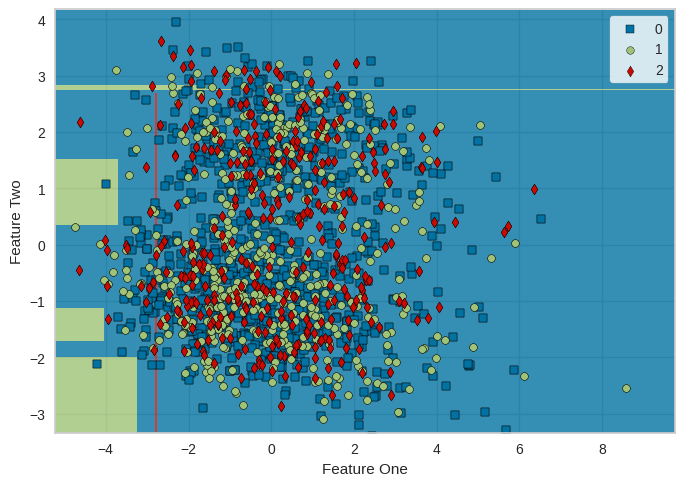

In [ ]:
# <> -----------------------------------------------
# <> Visualizando em forma de Gráfico
plot_model(tuned_dt, plot = 'boundary')


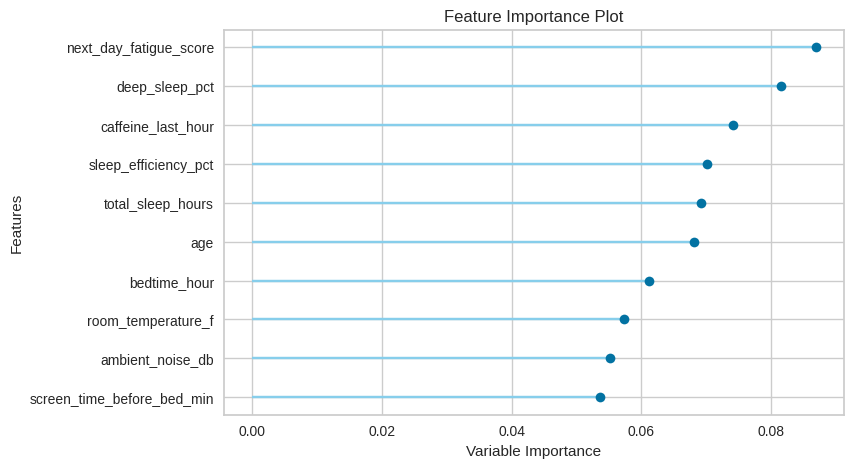

In [ ]:
# <> -------------------------------------------------
# <> Visualizando em forma de Gráfico
plot_model(tuned_dt, plot = 'feature')

Considerando o forte desbalanceamento da base, o max_deoth=2 e min_impurity_decrease=0.3, supeitando que a árvore ficou tão conservadora que está realizando poucas ou nenhuma divisão importante.

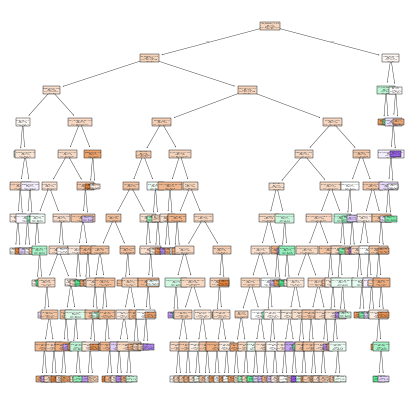

In [ ]:
# <> ------------------------------------------------------------
# <> Extrair o modelo treinado
trained_model = tuned_dt

# Plotar a árvore de decisão
plt.figure(figsize=(5,5))
plot_tree(trained_model, filled=True, feature_names=list(get_config('X_train_transformed').columns),
         class_names=sorted(y_test.unique()))
plt.show()

Observamos que com o forte desbalanceamento da base de dados, a árvore acabou ficando muito conservadora, levando a nenhuma divisão.

In [ ]:
# <> --------------------------------- # A parte de avaliar é no teste
# <> Fazendo predição do modelo
dt_testing_pred = predict_model(tuned_dt)

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Decision Tree Classifier,0.4676,0.5176,0.4676,0.3869,0.3949,0.0004,0.0005


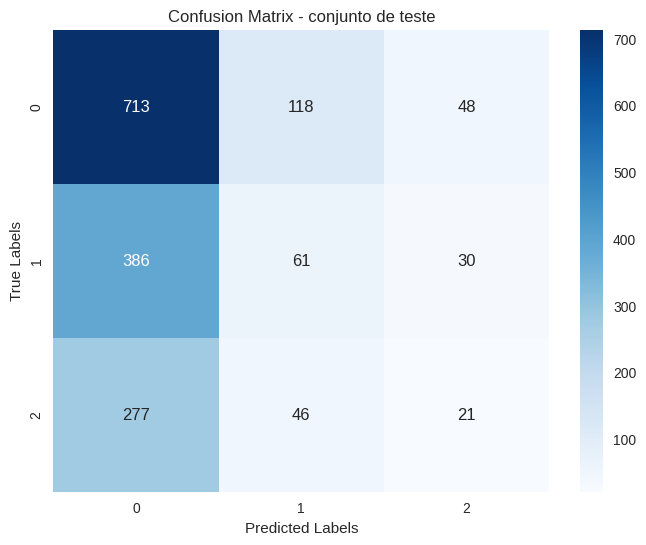

Accuracy: 0.4676470588235294
Kappa: 0.00039958027827668996
Classification Report:
              precision    recall  f1-score   support

        Mild       0.52      0.81      0.63       879
    Moderate       0.27      0.13      0.17       477
     No Debt       0.21      0.06      0.09       344

    accuracy                           0.47      1700
   macro avg       0.33      0.33      0.30      1700
weighted avg       0.39      0.47      0.39      1700



In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    cohen_kappa_score,
    classification_report
)
import seaborn as sns
import matplotlib.pyplot as plt


# Supondo que 'true_labels' seja a coluna de rótulos verdadeiros e 'predicted_labels' a coluna de rótulos previstos
true_labels = dt_testing_pred['sleep_debt_category']
predicted_labels = dt_testing_pred['prediction_label']

# Calcular a matriz de confusão
conf_matrix = confusion_matrix(
    true_labels,
    predicted_labels,
    labels=sorted(true_labels.unique())
)

# Plotar a matriz de confusão
plt.figure(figsize=(8,6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix - conjunto de teste')
plt.show()

# Calcular acurácia
accuracy = accuracy_score(true_labels, predicted_labels)

# Calcular coeficiente Kappa
kappa = cohen_kappa_score(true_labels, predicted_labels)

# Gerar relatório de classificação
classification_rep = classification_report(true_labels, predicted_labels)

# Exibir as métricas
print(f'Accuracy: {accuracy}')
print(f'Kappa: {kappa}')
print('Classification Report:')
print(classification_rep)

## Modelo 2: Random Forest